<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [symphase](https://github.com/Gokaran-Shukla/symphase) · MIT License — any reuse must keep this copyright notice and credit the author.

# SymPhase tutorial 18 — self-consistent anharmonic phonons (TDEP / SSCHA) in free energies and hulls

Strongly anharmonic solids need **temperature-dependent effective phonons**. TDEP fits effective force constants to MD at each $T$;
the SSCHA minimises a variational free energy. Both give

$$F(T) = F_\text{ph}[\omega_\text{eff}(T)](T) + \Delta F(T),\qquad \Delta F = \langle V - V_\text{eff}\rangle\ \ (\text{TDEP: } U_0)$$

SymPhase reads them and uses them everywhere a free energy is needed:
* **TDEP folders**: `outfile.free_energy` (T, F_ph, S, C_V; eV/atom) + `outfile.U0` (**second value** = baseline to add), one folder per temperature;
* **tables** `T F` (SSCHA or any code) with units eV | meV | Ry | mRy | Ha | kJ/mol, per atom or per cell;
* `AnharmonicF` → smooth $F(T)$ and $S=-\partial F/\partial T$;  `FreeEnergySurface` → anharmonic QHA over volumes;
* hull: `--vib scph`, CSV columns `scph`, `e_static` (required when $F$ contains the static energy, as TDEP's $U_0$ and SSCHA totals do).

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import numpy as np, math, os, copy, warnings
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")
from symphase import analyze_tensors
from symphase.tensors import read_poscar
from symphase.kubo import (SymTensor, plan, KuboTB, compute_symmetric, format_fit, read_hr, read_centres,
                           read_postw90_ahc, read_postw90_shc, haldane_hr, kane_mele_hr, honeycomb_lattice)
from symphase.qha import quartic_oscillator, AnharmonicF, FreeEnergySurface, QHA
from symphase.thermo import FiniteTHull
from symphase.hull import load_csv
KB = f"{EX}/kubo"
lat, frac = honeycomb_lattice(); cen = frac @ lat
def haldane(M=0.0, phi=math.pi / 2, efs=(0.0,), n=(60, 60)):
    R, H = haldane_hr(M=M, phi=phi)
    return KuboTB(lat, R, H, centres=cen, dims=2).conductivity([("charge", 0, 0, 1)], list(efs), n, 1e-6)[:, 0]
def kane_mele(efs=(0.0,), n=(60, 60)):
    R, H = kane_mele_hr()
    return KuboTB(lat, R, H, centres=np.r_[cen, cen], dims=2, spin_order="blocks").conductivity(
        [("spin", 2, 0, 1), ("charge", 0, 0, 1)], list(efs), n, 1e-6)
scph_csv = f"{EX}/hull/NiAl_scph.csv"

## 1. Why self-consistent phonons? A quartic oscillator, exactly

$V=\tfrac12kx^2+\lambda x^4$ ($k=2000$ meV/Å², $\lambda=1200$ meV/Å⁴, Fe mass). Exact quantum $F$ by diagonalisation vs the self-consistent
harmonic approximation (SCHA: $M\omega_\text{eff}^2=k+12\lambda\langle x^2\rangle$, $F=F_\text{ph}(\omega_\text{eff})+\langle V-V_\text{eff}\rangle$) vs plain harmonic:

1000 K: SCHA error +0.219 meV,  harmonic error -5.074 meV;  SCHA ≥ exact everywhere: True  (Gibbs–Bogoliubov bound)


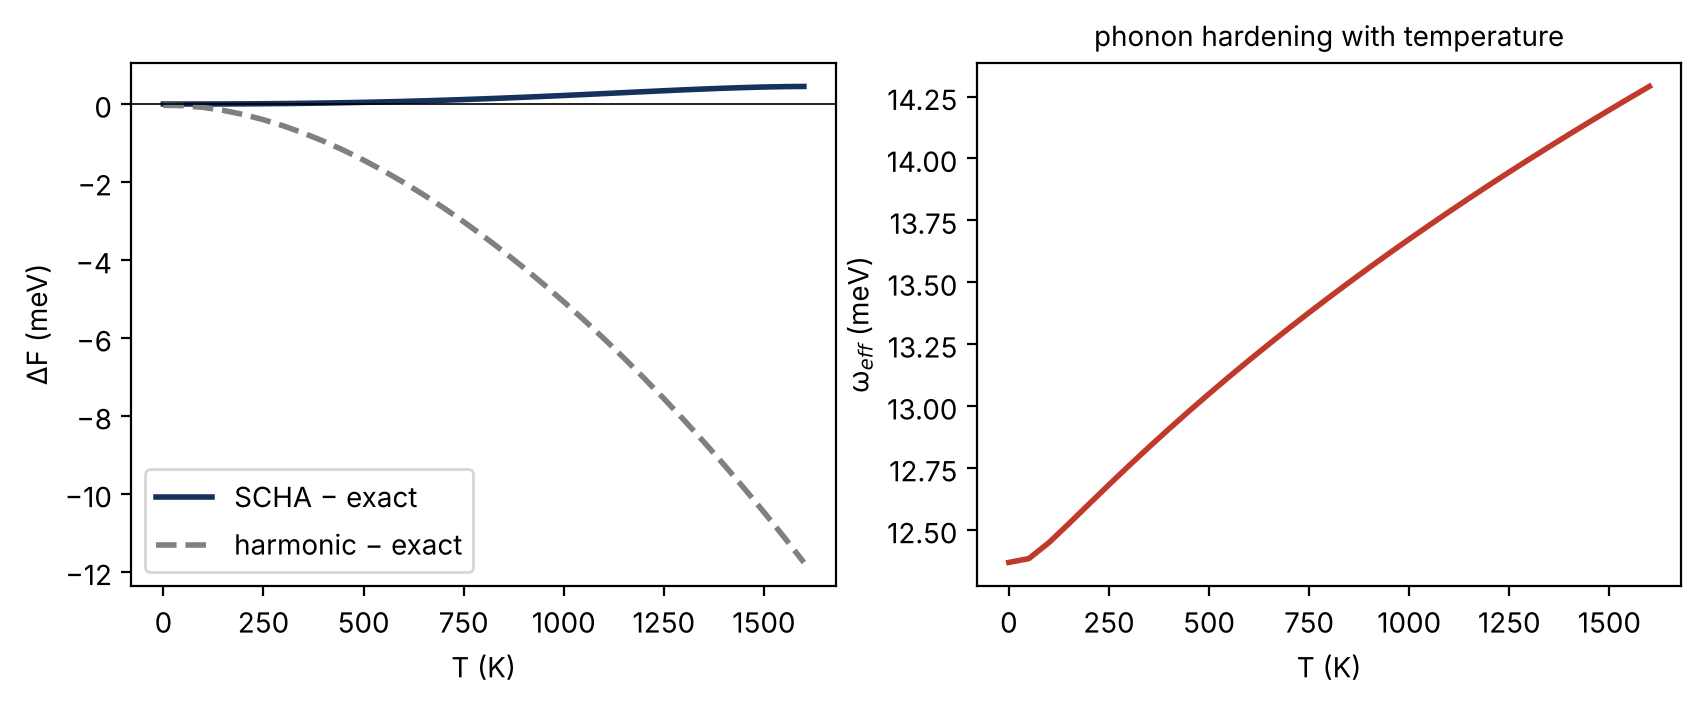

In [3]:
T = np.arange(0, 1601, 50)
q = quartic_oscillator(2000.0, 1200.0, 55.845, T)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.plot(T, q["scha"] - q["exact"], color="#16325c", lw=2, label="SCHA − exact")
a1.plot(T, q["harmonic"] - q["exact"], color="0.5", lw=2, ls="--", label="harmonic − exact")
a1.axhline(0, color="k", lw=0.6); a1.set_xlabel("T (K)"); a1.set_ylabel("ΔF (meV)"); a1.legend()
a2.plot(T, q["w_eff"], color="#c0392b", lw=2); a2.set_xlabel("T (K)"); a2.set_ylabel("ω$_{eff}$ (meV)")
a2.set_title("phonon hardening with temperature", fontsize=10)
k = int(np.argmin(abs(T - 1000)))
print(f"1000 K: SCHA error {q['scha'][k]-q['exact'][k]:+.3f} meV,  harmonic error {q['harmonic'][k]-q['exact'][k]:+.3f} meV;"
      f"  SCHA ≥ exact everywhere: {bool(np.all(q['scha'] >= q['exact'] - 1e-9))}  (Gibbs–Bogoliubov bound)")

## 2. Reading TDEP folders

`examples/hull/scph/Ni3Al-D019/T####/` contains `outfile.free_energy` and `outfile.U0` for every temperature (toy SCHA data,
written in TDEP's layout). `AnharmonicF.from_tdep` adds the baseline and builds a smooth $F(T)$:

In [4]:
F = AnharmonicF.from_tdep(f"{EX}/hull/scph/Ni3Al-D019", e_static=-5.52)
print("includes the static energy:", F.includes_static, " temperatures:", F.T.astype(int))
for t in (300, 750, 1300):
    print(f"T = {t:5d} K:  ΔF = F − E_static = {F.delta(t)*1e3:9.3f} meV/atom,  S = {F.entropy(t)/8.617333262e-5:.3f} k_B/atom")

includes the static energy: True  temperatures: [   0  100  200  300  400  500  600  700  800  900 1000 1200 1400 1600]
T =   300 K:  ΔF = F − E_static =   -63.018 meV/atom,  S = 5.378 k_B/atom
T =   750 K:  ΔF = F − E_static =  -329.218 meV/atom,  S = 7.935 k_B/atom
T =  1300 K:  ΔF = F − E_static =  -743.564 meV/atom,  S = 9.406 k_B/atom


## 3. Anharmonic quasi-harmonic approximation over volumes

With total free energies at several volumes, `FreeEnergySurface` minimises over $V$ at every $T$. Check: built from the
Debye–Grüneisen model it reproduces that model's $V(T)$ and $G(T)$:

In [5]:
qdg = QHA.debye_gruneisen(-5.0, 11.0, 180.0, 4.5, 450.0, 2.0)
Vs = 11.0 * np.linspace(0.95, 1.07, 9)
surf = FreeEnergySurface(Vs, [(lambda T, V=V: float(qdg.F(V, T))) for V in Vs])
for t in (300, 900):
    print(f"T = {t} K:  V surface {surf.equilibrium(t)[0]:.4f}  model {qdg.equilibrium(t)[0]:.4f} Å³;  "
          f"G {surf.G(t):.6f} / {qdg.G(t):.6f} eV")

T = 300 K:  V surface 11.1580  model 11.1585 Å³;  G -4.991346 / -4.991324 eV
T = 900 K:  V surface 11.4679  model 11.4695 Å³;  G -5.247021 / -5.247040 eV


## 4. Finite-temperature hull with anharmonic free energies

`examples/hull/NiAl_scph.csv`: the two Ni₃Al polymorphs come from TDEP-style folders, all other phases from SSCHA-style tables.
D0₁₉ is harmonically softer (it would win entropy early) but also more anharmonic: its phonons **harden** on heating.

T* (SCHA, hull from TDEP folders): 790 K;   same model, harmonic phonons only: 556 K


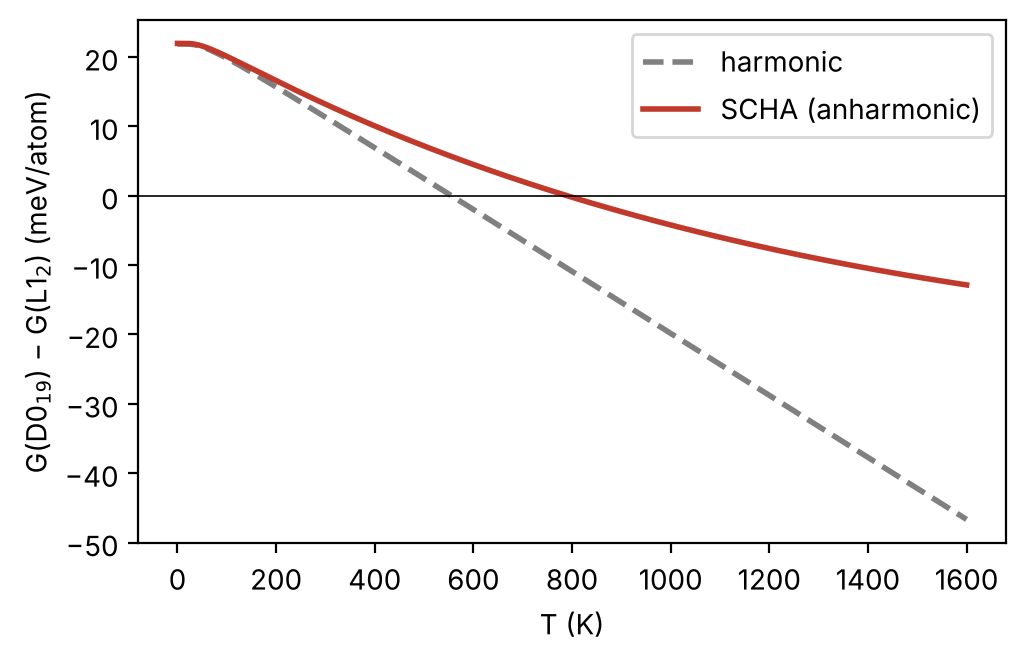

In [6]:
ft = FiniteTHull(load_csv(scph_csv), vib="scph", mixing=False)
Ts = ft.stabilisation_temperature("Ni3Al-D019", Tmax=1600)
Tg = np.arange(0, 1601, 1.0)
L, D = quartic_oscillator(2050, 500, 50, Tg), quartic_oscillator(1450, 1000, 50, Tg)
dH = 25 + 3 * (D["harmonic"] - L["harmonic"]); dS = 25 + 3 * (D["scha"] - L["scha"])
print(f"T* (SCHA, hull from TDEP folders): {Ts:.0f} K;   same model, harmonic phonons only: {Tg[np.argmax(dH <= 0)]:.0f} K")
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(Tg, dH, color="0.5", ls="--", lw=2, label="harmonic"); ax.plot(Tg, dS, color="#c0392b", lw=2, label="SCHA (anharmonic)")
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("T (K)"); ax.set_ylabel("G(D0$_{19}$) − G(L1$_2$) (meV/atom)"); ax.legend()

Anharmonic hardening delays the transition by ≈ 235 K here — the harmonic approximation would be badly wrong.

## 5. Command line
```bash
symphase hull --csv examples/hull/NiAl_scph.csv --temperatures 0 600 1200 --vib scph --no-mixing
```
CSV columns: `scph` (TDEP folder or table), `e_static` (eV/atom), `scph_unit`, `scph_per` (atom|cell), `scph_natom`, `scph_static`.
Continue with **19_quiz_kubo_anharmonic_phonons.ipynb**.